# Projet Data Mining - Saint-Honoré

## Questions 7 et 8

### 1. Préparation de l'environnement et des données

In [ ]:
# Importation des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Chargement des données nettoyées
df = pd.read_csv("../data/clean/clients_clean.csv")
df.head()

,client_id,boutique_principale,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav,carte_fidelite,canal_prefere,pays_residence,montant_prochain_achat_eur,est_revenu_6m,montant_total_eur,ville,surface_m2,vendeurs,ouverte_depuis_mois,pays_boutique
0,CT80059,BT15,4,4,1468.0,0,0,aucune,en ligne,USA,725.0,oui,5872.0,Séoul,483,8,236,Corée
1,CT80578,BT28,80,3,1235.0,1,1,argent,boutique,France,1479.0,oui,3705.0,Cannes,267,14,182,France
2,CT80256,BT27,43,1,1814.0,0,2,or,boutique,France,2307.0,oui,1814.0,Dubaï,519,12,209,EAU
3,CT80098,BT16,1,1,1795.0,0,0,or,boutique,Italie,1820.0,non,1795.0,Paris,139,21,266,France
4,CT80362,BT31,51,3,2022.0,0,0,argent,boutique,Chine,1201.0,oui,6066.0,Dubaï,108,17,73,EAU


In [ ]:
# Exploration des données
print(df.shape)

for col in df.columns:
    print(col)

(700, 18)
client_id
boutique_principale
anciennete_mois
nb_achats_12m
panier_moyen_eur
retours
demandes_sav
carte_fidelite
canal_prefere
pays_residence
montant_prochain_achat_eur
est_revenu_6m
montant_total_eur
ville
surface_m2
vendeurs
ouverte_depuis_mois
pays_boutique


In [5]:
# Importation des outils de Machine Learning
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### 2. Question 7 - Segmentation des clients

L'objectif est d'identifier des groupes de clients présentant des comportements similaires à l'aide d'une méthode de clustering.

In [6]:
# Sélection des variables pour le clustering

variables = [
    "anciennete_mois",
    "nb_achats_12m",
    "panier_moyen_eur",
    "retours",
    "demandes_sav"
]

X = df[variables]
X.head()

,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav
0,4,4,1468.0,0,0
1,80,3,1235.0,1,1
2,43,1,1814.0,0,2
3,1,1,1795.0,0,0
4,51,3,2022.0,0,0


In [7]:
# Standardisation des variables

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.10229382  0.11483504 -0.62441876 -0.63924005 -0.63906729]
 [ 2.02695011 -0.22868858 -0.7482204   0.66914602  0.95291528]
 [ 0.50350241 -0.91573583 -0.44057597 -0.63924005  2.54489784]
 [-1.22581661 -0.91573583 -0.45067138 -0.63924005 -0.63906729]
 [ 0.83289651 -0.22868858 -0.33005777 -0.63924005 -0.63906729]]


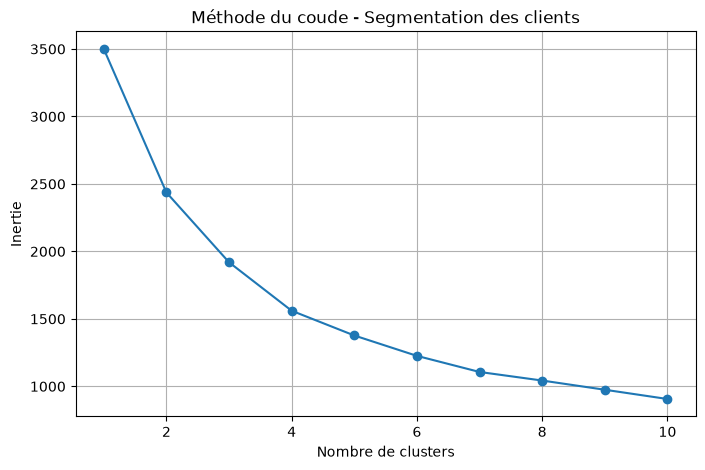

In [ ]:
# Méthode du coude

#Tester plusieurs nombres de groupes

inerties = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inerties.append(km.inertia_)

#Construction du graphique

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inerties, marker="o")
plt.xlabel("Nombre de clusters")
plt.ylabel("Inertie")
plt.title("Méthode du coude - Segmentation des clients")
plt.grid()
plt.show()

#### Interprétation de la méthode du coude

La courbe présente un changement de pente autour de 4 clusters.
Au-delà, la diminution de l'inertie devient moins importante.

Une segmentation en 4 groupes semble donc pertinente.
Ce choix sera évalué à l'aide du score de silhouette.

In [9]:
# Evaluation des clusters par le score de silhouette

scores = []

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    scores.append(score)
    print(k, round(score, 3))

2 0.459
3 0.3
4 0.297
5 0.299
6 0.304
7 0.298
8 0.308
9 0.309
10 0.307


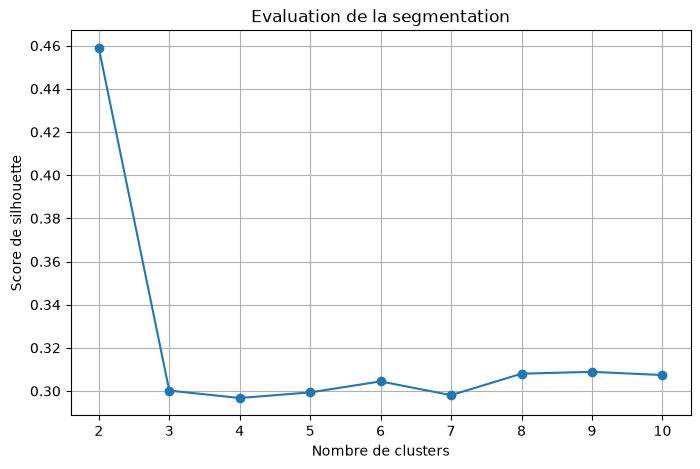

In [10]:
# Visualisation des scores de silhouette

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), scores, marker="o")
plt.xlabel("Nombre de clusters")
plt.ylabel("Score de silhouette")
plt.title("Evaluation de la segmentation")
plt.xticks(range(2, 11))
plt.grid()
plt.show()

#### Interprétation du score de silhouette

Le score de silhouette atteint son maximum pour
k = 2, avec une valeur de 0,459.

Contrairement à la méthode du coude, qui suggère
4 clusters, le score de silhouette favorise une
segmentation en 2 groupes.

Une comparaison des profils obtenus avec ces deux
configurations permettra de retenir la segmentation
la plus pertinente pour Saint-Honoré.

In [11]:
# Comparaison des segmentations en 2 et 4 clusters

km2 = KMeans(n_clusters=2, n_init=10, random_state=42)
df["cluster_2"] = km2.fit_predict(X_scaled)

km4 = KMeans(n_clusters=4, n_init=10, random_state=42)
df["cluster_4"] = km4.fit_predict(X_scaled)

print(df["cluster_2"].value_counts())
print(df["cluster_4"].value_counts())

cluster_2
0    601
1     99
Name: count, dtype: int64
cluster_4
3    252
1    179
2    174
0     95
Name: count, dtype: int64


In [12]:
# Analyse des profils pour les deux segmentations

print("Segmentation en 2 clusters")
display(df.groupby("cluster_2")[variables].mean().round(2))

print("Segmentation en 4 clusters")
display(df.groupby("cluster_4")[variables].mean().round(2))

Segmentation en 2 clusters


,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav
cluster_2,,,,,
0,33.43,2.74,2041.04,0.35,0.42
1,14.61,9.26,6298.62,1.35,0.29


Segmentation en 4 clusters


,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav
cluster_4,,,,,
0,14.88,9.37,6414.14,1.35,0.25
1,63.36,3.56,1718.75,0.40,0.20
2,24.35,2.63,2162.42,0.36,1.28
3,18.05,2.31,2210.19,0.32,0.00


### Comparaison et choix de la segmentation

La segmentation en 2 clusters distingue principalement
les clients classiques des clients à forte valeur.

La segmentation en 4 clusters permet d'identifier
des profils plus précis selon leur ancienneté,
leurs habitudes d'achat et leurs demandes SAV.

Nous retenons la segmentation en 4 clusters pour
son intérêt commercial, malgré un score de silhouette
inférieur à celui de la segmentation en 2 clusters.

In [13]:
# Segmentation finale des clients

df["cluster"] = df["cluster_4"]

df["cluster"].value_counts().sort_index()

cluster
0     95
1    179
2    174
3    252
Name: count, dtype: int64

In [14]:
# Analyse de la carte de fidélité par cluster

pd.crosstab(df["cluster"], df["carte_fidelite"])

carte_fidelite,argent,aucune,inconnue,or
cluster,,,,
0,29,47,3,16
1,65,88,5,21
2,64,77,6,27
3,84,124,7,37


In [15]:
# Répartition des cartes de fidélité en pourcentage

pd.crosstab(df["cluster"], df["carte_fidelite"],
            normalize="index").mul(100).round(2)

carte_fidelite,argent,aucune,inconnue,or
cluster,,,,
0,30.53,49.47,3.16,16.84
1,36.31,49.16,2.79,11.73
2,36.78,44.25,3.45,15.52
3,33.33,49.21,2.78,14.68


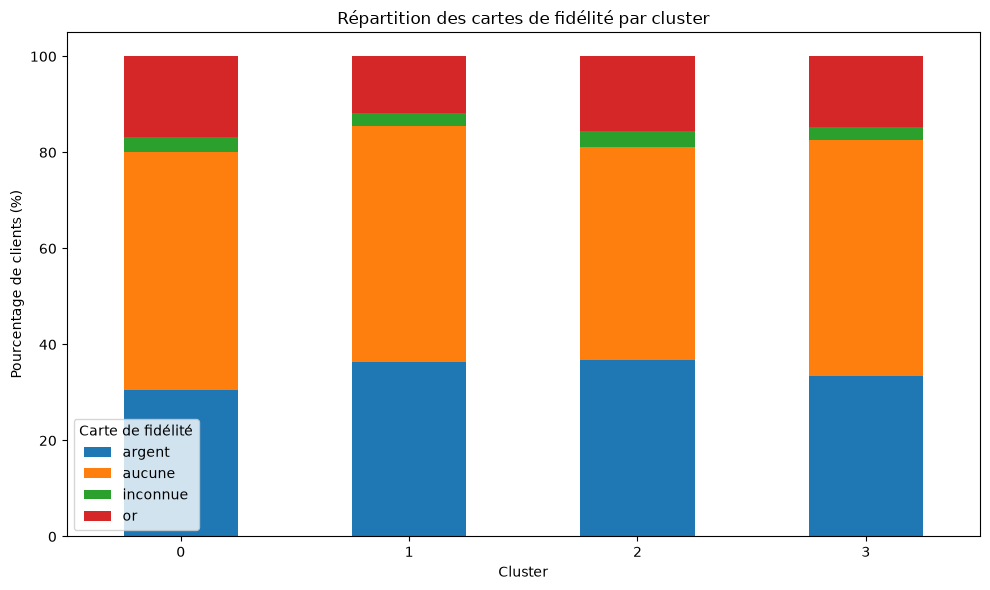

In [16]:
# Visualisation des cartes de fidélité par cluster

fidelite = pd.crosstab(df["cluster"], df["carte_fidelite"],
                       normalize="index") * 100

fidelite.plot(kind="bar", stacked=True, figsize=(10, 6))

plt.title("Répartition des cartes de fidélité par cluster")
plt.xlabel("Cluster")
plt.ylabel("Pourcentage de clients (%)")
plt.legend(title="Carte de fidélité")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interprétation de la fidélité des clients

La répartition des cartes de fidélité est relativement
similaire entre les quatre clusters.

Entre 44 % et 50 % des clients de chaque groupe
ne possèdent aucune carte de fidélité.

Le cluster 0, qui regroupe les clients à forte valeur
commerciale, compte 49,47 % de clients sans carte.

Saint-Honoré pourrait donc renforcer son programme
de fidélité, notamment auprès de ses clients premium.

### Caractérisation des profils clients

In [17]:
# Attribution de noms commerciaux aux clusters
noms_clusters = {
    0: "Clients premium",
    1: "Clients historiques",
    2: "Clients sollicitant le SAV",
    3: "Clients occasionnels"
}

df["profil_client"] = df["cluster"].map(noms_clusters)

df["profil_client"].value_counts()

profil_client
Clients occasionnels          252
Clients historiques           179
Clients sollicitant le SAV    174
Clients premium                95
Name: count, dtype: int64

In [18]:
# Synthèse des caractéristiques de chaque profil
synthese = df.groupby("profil_client")[variables].mean()

synthese["Effectif"] = df["profil_client"].value_counts()

synthese["Pourcentage (%)"] = synthese["Effectif"] / len(df) * 100

display(synthese.round(2))

,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav,Effectif,Pourcentage (%)
profil_client,,,,,,,
Clients historiques,63.36,3.56,1718.75,0.40,0.20,179,25.57
Clients occasionnels,18.05,2.31,2210.19,0.32,0.00,252,36.00
Clients premium,14.88,9.37,6414.14,1.35,0.25,95,13.57
Clients sollicitant le SAV,24.35,2.63,2162.42,0.36,1.28,174,24.86


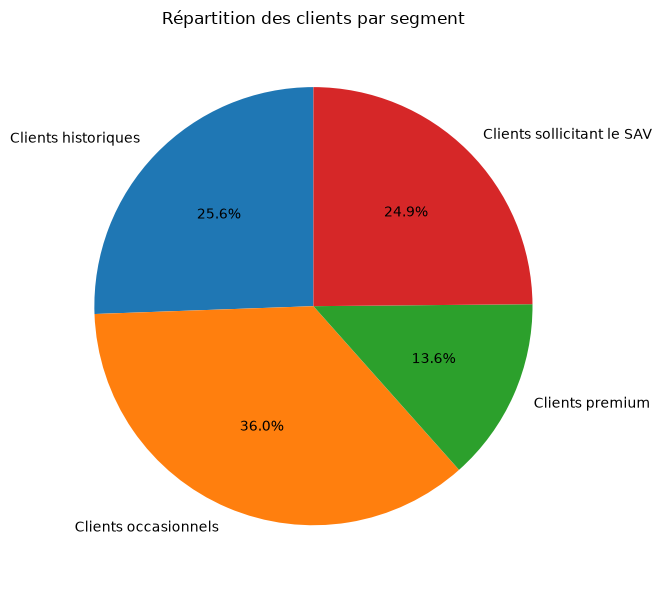

In [19]:
# Répartition des clients par profil
plt.figure(figsize=(9, 6))

plt.pie(
    synthese["Effectif"],
    labels=synthese.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Répartition des clients par segment")
plt.tight_layout()
plt.show()

### Recommandations marketing par segment

#### Cluster 0 - Clients premium (13,57 %)
- Proposer des avantages VIP et des invitations exclusives.
- Encourager l'adhésion au programme de fidélité.
- Personnaliser les recommandations de produits.

#### Cluster 1 - Clients historiques (25,57 %)
- Récompenser leur ancienneté.
- Proposer des avantages personnalisés.
- Renforcer leur engagement envers la marque.

#### Cluster 2 - Clients sollicitant le SAV (24,86 %)
- Améliorer la prise en charge des demandes.
- Mettre en place un suivi personnalisé.
- Mesurer leur satisfaction après chaque intervention.

#### Cluster 3 - Clients occasionnels (36 %)
- Mettre en place des campagnes de réactivation.
- Encourager les achats répétés.
- Proposer des offres personnalisées.

### Conclusion de la question 7

L'application de l'algorithme K-Means sur les données
de 700 clients a permis d'identifier quatre profils
aux comportements d'achat distincts.

Bien que la segmentation en deux clusters présente
un meilleur score de silhouette, la segmentation
en quatre clusters offre une interprétation
commerciale plus détaillée.

L'analyse des cartes de fidélité révèle également
une opportunité de développement du programme
de fidélisation, notamment auprès des clients premium.

Cette segmentation permet à Saint-Honoré d'adapter
ses stratégies marketing, d'améliorer l'expérience
client et de favoriser la fidélisation.

Les trois niveaux du programme de fidélité existant
ne reflètent pas entièrement les quatre profils
comportementaux identifiés par notre analyse.